# 5. Elimination, LU and the Four Fundamental Subspaces
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Elimination on a $5\times5$ matrix, step by step. Top row, the remaining matrix after $0,1,\dots,4$ steps; the active part shrinks by one row and column each time. Bottom row, the rank-one piece $\ell_ku_k^{\mathsf T}$ removed at each step. The five pieces add up to $A=LU$.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


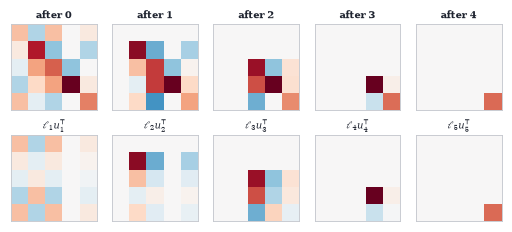

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *

rng = np.random.default_rng(11)
A = rng.integers(-4, 5, size=(5, 5)).astype(float) + 6 * np.eye(5)
R = A.copy(); stages, pieces = [R.copy()], []
for k in range(5):
    l = R[:, k] / R[k, k]; l[:k] = 0
    piece = np.outer(l, R[k]); pieces.append(piece)
    R = R - piece; stages.append(R.copy())
v = np.abs(A).max()
fig, axs = plt.subplots(2, 5, figsize=(W, 2.0))
for k in range(5):
    heat(axs[0, k], stages[k], annot=False, vmax=v); axs[0, k].set_title(f"after {k}", fontsize=6.5)
    heat(axs[1, k], pieces[k], annot=False, vmax=v); axs[1, k].set_title(rf"$\ell_{k+1}u_{k+1}^{{\mathsf{{T}}}}$", fontsize=6.5)

In [3]:
def lu_nopivot(A):
    """Doolittle LU without row exchanges: returns L (unit lower) and U."""
    A = np.array(A, dtype=float); n = A.shape[0]
    L, U = np.eye(n), A.copy()
    for k in range(n - 1):
        if U[k, k] == 0:
            raise ZeroDivisionError(f"zero pivot at step {k}")
        L[k + 1:, k] = U[k + 1:, k] / U[k, k]
        U[k + 1:, :] -= np.outer(L[k + 1:, k], U[k, :])
    return L, U

def forward(L, b):
    c = np.zeros_like(b, dtype=float)
    for i in range(len(b)):
        c[i] = (b[i] - L[i, :i] @ c[:i]) / L[i, i]
    return c

def backward(U, c):
    x = np.zeros_like(c, dtype=float)
    for i in reversed(range(len(c))):
        x[i] = (c[i] - U[i, i + 1:] @ x[i + 1:]) / U[i, i]
    return x

A = np.array([[2, 1, 1], [4, -6, 0], [-2, 7, 2]], float); b = np.array([5, -2, 9.0])
L, U = lu_nopivot(A)
print("L =\n", L, "\nU =\n", U)
x = backward(U, forward(L, b))
print("x =", x, "  residual:", np.abs(A @ x - b).max())

L =
 [[ 1.  0.  0.]
 [ 2.  1.  0.]
 [-1. -1.  1.]] 
U =
 [[ 2.  1.  1.]
 [ 0. -8. -2.]
 [ 0.  0.  1.]]
x = [1. 1. 2.]   residual: 0.0


In [4]:
eps = 1e-20
A = np.array([[eps, 1.0], [1.0, 1.0]]); b = np.array([1.0, 2.0])      # exact solution ~ (1, 1)
L, U = lu_nopivot(A)
print("no pivoting:      x =", backward(U, forward(L, b)), "   U =", U.ravel())
P = np.array([[0, 1], [1, 0.0]])                                      # exchange the rows first
L, U = lu_nopivot(P @ A)
print("partial pivoting: x =", backward(U, forward(L, P @ b)))
print("numpy.linalg.solve:   ", np.linalg.solve(A, b))

no pivoting:      x = [0. 1.]    U = [ 1.e-20  1.e+00  0.e+00 -1.e+20]
partial pivoting: x = [1. 1.]
numpy.linalg.solve:    [1. 1.]


Accuracy of elimination with and without pivoting on random $50\times50$ matrices whose $(1,1)$ entry has been scaled down to $\delta$. Without pivoting the relative error grows like $1/\delta$ until the answer is meaningless; with partial pivoting it stays at the level of rounding error.

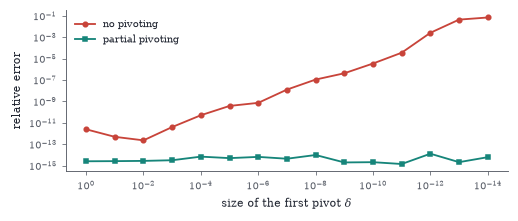

In [5]:
rng = np.random.default_rng(0)
deltas = 10.0 ** -np.arange(0, 15)
err_np, err_pp = [], []
import scipy.linalg as sla
for d in deltas:
    A = rng.normal(size=(50, 50)); A[0, 0] = d
    x_true = rng.normal(size=50); b = A @ x_true
    L, U = lu_nopivot(A); x1 = backward(U, forward(L, b))
    x2 = sla.lu_solve(sla.lu_factor(A), b)
    err_np.append(np.linalg.norm(x1 - x_true) / np.linalg.norm(x_true))
    err_pp.append(np.linalg.norm(x2 - x_true) / np.linalg.norm(x_true))
fig, ax = plt.subplots(figsize=(W, 1.9))
ax.loglog(deltas, err_np, "o-", color=RED, ms=3, label="no pivoting")
ax.loglog(deltas, err_pp, "s-", color=TEAL, ms=3, label="partial pivoting")
ax.invert_xaxis(); ax.set_xlabel(r"size of the first pivot $\delta$"); ax.set_ylabel("relative error"); ax.legend()

In [6]:
from fractions import Fraction

def rref(A):
    """Exact reduced row echelon form with Fractions. Returns R and the pivot columns."""
    R = [[Fraction(x) for x in row] for row in A]
    m, n = len(R), len(R[0]); piv = []; r = 0
    for c in range(n):
        p = next((i for i in range(r, m) if R[i][c] != 0), None)
        if p is None:
            continue
        R[r], R[p] = R[p], R[r]
        R[r] = [x / R[r][c] for x in R[r]]
        for i in range(m):
            if i != r and R[i][c] != 0:
                f = R[i][c]; R[i] = [a - f * b for a, b in zip(R[i], R[r])]
        piv.append(c); r += 1
        if r == m:
            break
    return R, piv

def nullspace_basis(A):
    R, piv = rref(A); n = len(A[0])
    free = [c for c in range(n) if c not in piv]
    basis = []
    for f in free:
        s = [Fraction(0)] * n; s[f] = Fraction(1)
        for i, p in enumerate(piv):
            s[p] = -R[i][f]
        basis.append(s)
    return basis

A = [[1, 2, 2, 4], [3, 8, 6, 16], [2, 6, 4, 12]]
R, piv = rref(A)
for row in R: print([str(x) for x in row])
print("pivot columns:", piv)
print("special solutions:", [[str(x) for x in s] for s in nullspace_basis(A)])

['1', '0', '2', '0']
['0', '1', '0', '2']
['0', '0', '0', '0']
pivot columns: [0, 1]
special solutions: [['-2', '0', '1', '0'], ['0', '-2', '0', '1']]


The solution set of two equations in three unknowns, $x_1+x_2+x_3=2$ and $x_1-x_2+2x_3=1$, is a line in $\R^3$ (red): a particular solution $x_p$ (black dot) plus every multiple of the special solution $s$ spanning the null space (grey line through the origin, parallel to the red one). The two planes are the row picture of the system.

[]

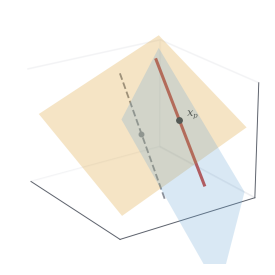

In [7]:
A = np.array([[1.0, 1.0, 1.0], [1.0, -1.0, 2.0]]); b = np.array([2.0, 1.0])
xp = np.linalg.lstsq(A, b, rcond=None)[0]
s = np.cross(A[0], A[1]); s = s / np.linalg.norm(s)
fig = plt.figure(figsize=(W * 0.62, W * 0.52))
ax = ax3d(fig, elev=22, azim=-35, lim=2.2)
plane3d(ax, A[0], b[0], lim=2.0, color=SKY, alpha=0.25)
plane3d(ax, A[1], b[1], lim=2.0, color=GOLD, alpha=0.25)
t = np.array([-2.5, 2.5])
ax.plot(*(xp[:, None] + np.outer(s, t)), color=RED, lw=2)
ax.plot(*np.outer(s, t), color=GRAY, lw=1.2, ls="--")
ax.scatter(*xp, color=INK, s=12); ax.scatter(0, 0, 0, color=GRAY, s=8)
ax.text(*(xp + 0.15), "$x_p$", fontsize=7)
ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

The four fundamental subspaces of a real $m\times n$ matrix of rank $r$. In $\R^n$ (left) the row space and the null space are orthogonal and their dimensions add to $n$; in $\R^m$ (right) the column space and the left null space are orthogonal with dimensions adding to $m$. The matrix maps the row space one-to-one onto the column space and the null space to zero.

Text(5.5, 2.6, '$0$')

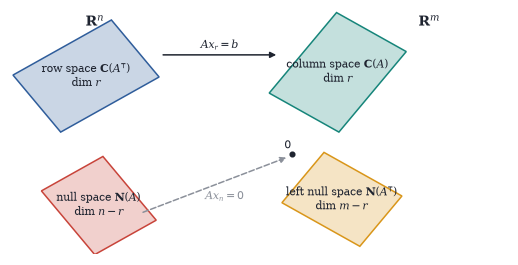

In [8]:
from matplotlib.patches import Polygon, FancyArrowPatch
fig, ax = plt.subplots(figsize=(W, 2.3))
ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.axis("off")
def box(x0, y0, w, h, ang, col, label, dim):
    c, s = np.cos(ang), np.sin(ang)
    P = np.array([[0, 0], [w, 0], [w, h], [0, h]]) @ np.array([[c, s], [-s, c]]) + [x0, y0]
    ax.add_patch(Polygon(P, closed=True, color=col, alpha=0.25, lw=0))
    ax.add_patch(Polygon(P, closed=True, fill=False, ec=col, lw=1))
    ctr = P.mean(0); ax.text(*ctr, label + "\n" + dim, ha="center", va="center", fontsize=7, color=INK)
box(1.0, 3.0, 2.4, 1.7, 0.6, BLUE, r"row space $\mathbf{C}(A^{\mathsf{T}})$", "dim $r$")
box(1.85, 2.4, 1.5, 1.9, 0.6 + np.pi, RED, r"null space $\mathbf{N}(A)$", "dim $n-r$")
box(6.6, 3.0, 2.4, 1.7, -0.6 + np.pi / 2, TEAL, r"column space $\mathbf{C}(A)$", "dim $r$")
box(6.3, 2.5, 1.5, 1.9, -0.6 - np.pi / 2, GOLD, r"left null space $\mathbf{N}(A^{\mathsf{T}})$", "dim $m-r$")
ax.text(1.5, 5.6, r"$\mathbf{R}^n$", fontsize=9); ax.text(8.2, 5.6, r"$\mathbf{R}^m$", fontsize=9)
ax.add_patch(FancyArrowPatch((3.0, 4.9), (5.4, 4.9), arrowstyle="-|>", mutation_scale=8, color=INK, lw=1))
ax.text(4.2, 5.05, r"$Ax_r=b$", ha="center", fontsize=7)
ax.add_patch(FancyArrowPatch((2.6, 1.0), (5.6, 2.4), arrowstyle="-|>", mutation_scale=8, color=GRAY, lw=1, ls="--"))
ax.text(4.3, 1.35, r"$Ax_n=0$", ha="center", fontsize=7, color=GRAY)
ax.plot([5.65], [2.45], "o", color=INK, ms=3); ax.text(5.5, 2.6, "$0$", fontsize=7)

A graph with $4$ nodes and $5$ oriented edges. Left, a vector in the left null space: unit circulation around the loop $1\to2\to3\to1$ (forward on edges $1$ and $3$, backward on edge $2$). Right, a second independent circulation, around the loop through nodes $2,3,4$. Together they span the left null space $\mathbf N(A^{\mathsf T})$, of dimension $m-r=2$.

A^T y1 = [0. 0. 0. 0.]  A^T y2 = [0. 0. 0. 0.]  rank A = 3


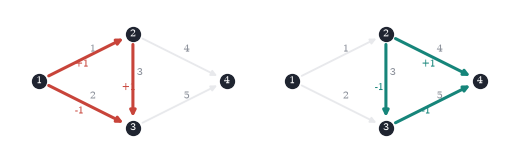

In [9]:
pos = {1: (0, 0.5), 2: (1, 1), 3: (1, 0), 4: (2, 0.5)}
edges = [(1, 2), (1, 3), (2, 3), (2, 4), (3, 4)]
A = np.zeros((5, 4))
for k, (i, j) in enumerate(edges):
    A[k, i - 1], A[k, j - 1] = -1, 1
y1 = np.array([1, -1, 1, 0, 0.0]); y2 = np.array([0, 0, -1, 1, -1.0])
print("A^T y1 =", A.T @ y1, " A^T y2 =", A.T @ y2, " rank A =", np.linalg.matrix_rank(A))
fig, axs = plt.subplots(1, 2, figsize=(W, 1.6))
for ax, y, col in [(axs[0], y1, RED), (axs[1], y2, TEAL)]:
    for k, (i, j) in enumerate(edges):
        p, q = np.array(pos[i]), np.array(pos[j])
        on = y[k] != 0
        ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color=col if on else LIGHT, lw=2.0 if on else 1.2, shrinkA=7, shrinkB=7))
        m = (p + q) / 2; ax.text(*(m + [0.04, 0.06]), f"{k+1}", fontsize=6.5, color=GRAY)
        if on:
            ax.text(*(m - [0.12, 0.1]), f"{y[k]:+.0f}", fontsize=6.5, color=col)
    for n, p in pos.items():
        ax.plot(*p, "o", color=INK, ms=9); ax.text(*p, str(n), color="white", ha="center", va="center", fontsize=6.5)
    ax.set_xlim(-0.3, 2.3); ax.set_ylim(-0.25, 1.25); ax.axis("off"); ax.set_aspect("equal")

The "wheel" graph of the previous problem with its four triangular loops (coloured). Each loop gives a vector $y$ with $A^{\mathsf T}y=0$; the four are independent and span the left null space.

rank A = 4 | A^T Y = 0: True | rank Y = 4


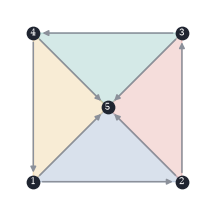

In [10]:
pos = {1: (0, 0), 2: (1, 0), 3: (1, 1), 4: (0, 1), 5: (0.5, 0.5)}
edges = [(1, 2), (2, 3), (3, 4), (4, 1), (1, 5), (2, 5), (3, 5), (4, 5)]
A = np.zeros((8, 5))
for k, (i, j) in enumerate(edges):
    A[k, i - 1], A[k, j - 1] = -1, 1
loops = []
for c in range(4):                         # triangle: corner a -> corner b -> centre -> a
    a, b = c + 1, (c + 1) % 4 + 1
    y = np.zeros(8); y[c] = 1              # square edge a -> b
    y[4 + b - 1] = 1                       # spoke b -> 5
    y[4 + a - 1] = -1                      # spoke a -> 5 traversed backwards
    loops.append(y)
Y = np.array(loops).T
print("rank A =", np.linalg.matrix_rank(A), "| A^T Y = 0:", np.allclose(A.T @ Y, 0), "| rank Y =", np.linalg.matrix_rank(Y))
fig, ax = plt.subplots(figsize=(W * 0.4, W * 0.4))
cols = [BLUE, RED, TEAL, GOLD]
for c in range(4):
    a, b = c + 1, (c + 1) % 4 + 1
    tri = np.array([pos[a], pos[b], pos[5]])
    ax.fill(*tri.T, color=cols[c], alpha=0.18)
for (i, j) in edges:
    ax.annotate("", xy=pos[j], xytext=pos[i], arrowprops=dict(arrowstyle="-|>", color=GRAY, lw=1.0, shrinkA=6, shrinkB=6))
for n, p in pos.items():
    ax.plot(*p, "o", color=INK, ms=8); ax.text(*p, str(n), color="white", ha="center", va="center", fontsize=6)
ax.set_xlim(-0.15, 1.15); ax.set_ylim(-0.15, 1.15); ax.axis("off"); ax.set_aspect("equal")

In [11]:
for c in [0.0, 1.0, 2.0, 3.0]:
    A = np.array([[1, c, 0], [2, 4, 1], [3, 5, 1.0]])
    try:
        L, U = lu_nopivot(A); print(f"c={c}: pivots", np.diag(U).round(4), " det", round(np.linalg.det(A), 6))
    except ZeroDivisionError as e:
        print(f"c={c}: {e};  det", round(np.linalg.det(A), 6))

c=0.0: pivots [ 1.    4.   -0.25]  det -1.0
c=1.0: pivots [1. 2. 0.]  det 0.0
c=2.0: zero pivot at step 1;  det 1.0
c=3.0: pivots [ 1. -2. -1.]  det 2.0


In [12]:
A = [[2, -1, 0], [-1, 2, -1], [0, -1, 2]]
aug = [row + [int(i == j) for j in range(3)] for i, row in enumerate(A)]
R, piv = rref(aug)
Ainv = [[str(x) for x in row[3:]] for row in R]
print(Ainv)

[['3/4', '1/2', '1/4'], ['1/2', '1', '1/2'], ['1/4', '1/2', '3/4']]


Operation count of elimination (multiply–subtract pairs, counted by instrumenting the algorithm) against the size $n$, on log–log axes. The points lie on a line of slope $3$, close to $n^3/3$ (dashed).

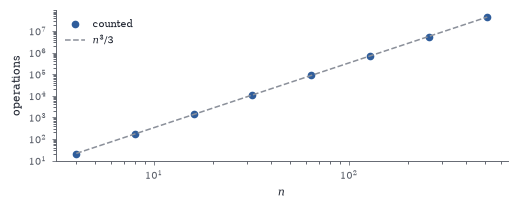

In [13]:
def count_ops(n):
    return sum((n - k) * (n - k + 1) for k in range(1, n))
ns = np.array([4, 8, 16, 32, 64, 128, 256, 512])
fig, ax = plt.subplots(figsize=(W, 1.8))
ax.loglog(ns, [count_ops(n) for n in ns], "o", color=BLUE, ms=4, label="counted")
ax.loglog(ns, ns ** 3 / 3, "--", color=GRAY, lw=1, label=r"$n^3/3$")
ax.set_xlabel("$n$"); ax.set_ylabel("operations"); ax.legend()